# This is a notebook that predicts car used car value from Craigslist

### About the project
Craigslist is the world's largest collection of used vehicles for sale. Using data from this platform, this notebook will create a ML model to predict the true value of an used car based on its features.

Data is coming from [kaggle](https://www.kaggle.com/datasets/austinreese/craigslist-carstrucks-data) and contains 26 features.

### Project Steps
- Environment creation
- Data collection
- Data preparation
- Exploratory Data Analysis
- Feature Engineering
- Model development
- Results

### Step 0: Environment creation

This step involvees download of the required packages and their import into the working environment

In [2]:
#%pip install numpy; pandas; matplotlib; scikit-learn; kagglehub; xgboost

In [3]:
import numpy as np
import pandas as pd
import scipy
import kagglehub
import matplotlib.pyplot as plt
import seaborn as sns

c:\D_Folder\GitFiles\DataScienceProjects\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Step 1: Data Collection

Data will be downloaded from kaggle

Dataset features: <StringArray>
[          'id',          'url',       'region',   'region_url',
        'price',         'year', 'manufacturer',        'model',
    'condition',    'cylinders',         'fuel',     'odometer',
 'title_status', 'transmission',          'VIN',        'drive',
         'size',         'type',  'paint_color',    'image_url',
  'description',       'county',        'state',          'lat',
         'long', 'posting_date']
Length: 26, dtype: str
<class 'pandas.DataFrame'>
RangeIndex: 426880 entries, 0 to 426879
Data columns (total 26 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            426880 non-null  int64  
 1   url           426880 non-null  str    
 2   region        426880 non-null  str    
 3   region_url    426880 non-null  str    
 4   price         426880 non-null  int64  
 5   year          425675 non-null  float64
 6   manufacturer  409234 non-null  str    
 7   model         421603 

<Axes: >

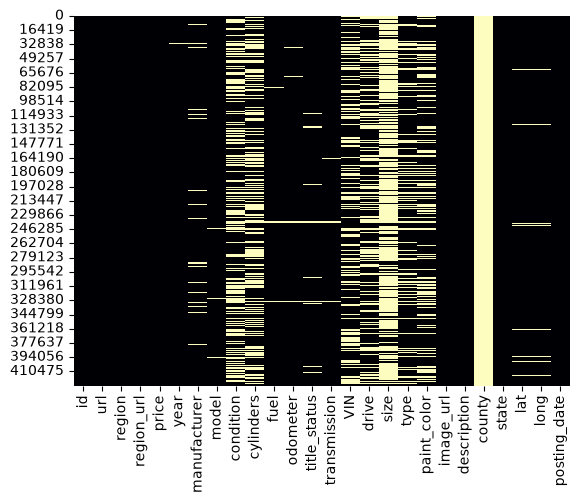

In [4]:
handle = 'austinreese/craigslist-carstrucks-data'
output_dir = 'Data'

#dataset = kagglehub.dataset_download(handle=handle, output_dir=output_dir)

df = pd.read_csv(f'{output_dir}\\vehicles.csv')
df.head()

print('Dataset features:', df.columns.values)
print('Dataset info:', df.info())
print('Null values:', df.isna().sum())
sns.heatmap(df.isnull(),cmap = 'magma',cbar = False)

#### Data collection conclusions
- There are a lot of missing values
- County column has no valu so it will be the first to be dropped
- Few numeric values:
    - useful: price(target), year, odometer
    - not useful: id, county, lat and long
- Loads of categorical features - need to check which one will have impact
- Condition feature has loads of missing values
- Cylinder feature can be mapped from string to numeric value

### Step 2: Data preparation

In [5]:
#print(df['VIN'].tail())

False    298027
True     128853
Name: count, dtype: int64


<Axes: >

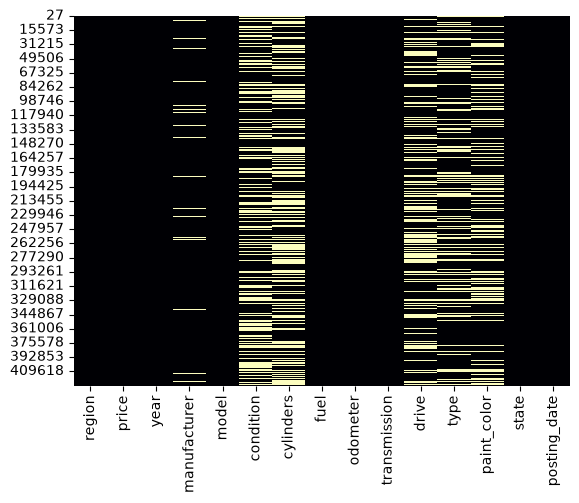

In [6]:
#Features to be checked when looking for a duplicate
key = ['VIN', 'year','manufacturer','model','fuel','odometer','transmission',
       'paint_color','state','price']          # no region, no posting_date

#Extract duplicates
df_duplicated = df.duplicated(subset=key)
print(df_duplicated.value_counts())
df = df.loc[~df_duplicated].copy()



#Eliminate irrelevant features
irrelevant_features = ['id', 'url', 'region_url', 'title_status', 'VIN', 'image_url', 'description', 'lat', 'long']

df = df.drop(columns=irrelevant_features, errors='ignore')

#Create a visualization of missing data
sns.heatmap(df.isnull(),cmap = 'magma',cbar = False)

#Determine how much of each feature is nan and remove features with more than 50% missing values
length = len(df)
cutoff = 50 #Will discard data with cutoff values over 50%
col_missing_over_cutoff = []

for column in df.columns.values:
    missing_percent = (df[column].isna().sum()/length)*100
    if missing_percent > 50:
        col_missing_over_cutoff.append(column)

df = df.drop(columns = col_missing_over_cutoff)

#Drop rows with missing data for columns: year, model, fuel, odometer and transmision since there are few missing values
df = df.dropna(subset=['year', 'model', 'fuel', 'odometer', 'transmission'])

#Transform dtype of year from float to integer
df['year'] = df['year'].astype('int64')

#Transform posting_date from string to datetime 
df['posting_date'] = pd.to_datetime(df['posting_date'], utc=True)

sns.heatmap(df.isnull(),cmap = 'magma',cbar = False)


Based on the remaining features and their missing values I can do the following things:
- There are columns where few values are missing
    - for year, model fuel odometer and transmision just drop the rows
    - for manufacturer I can determine it based on the model - but it might not bring new info to the model
- There are columns where loads of values are missing
    - paint color could be ignored for the moment.
    - I guess that drive, type and possiblly cylinders are missing when only one possibility exists
    - Exploratory Data Analysis needs to be performed to understand the data better

### Step 3: Exploratory Data Analysis

In this step multiple visualizations will be created to understand how features relate to the target and to each other.
Another important step is to check the relation of missing values to the rest of the features

#### Step 3.1 Price distribution

##### Get some information about the price: min, max and see the count of each price

VISUALIZATION BEFORE PRICE FILTERING
Minimum price value is: 0, and maximum price is 3736928711
IQR: 19090.0, Upper range based on IQR is: 53225.0
Value counts of the price
            price  count
0               0  18070
52              1    906
1716            2     12
1958            3      9
3621            4      4
...           ...    ...
8272   1111111111      1
10730  1234567890      1
11127  1410065407      1
6023   3024942282      2
7483   3736928711      2

[15318 rows x 2 columns]
Price ranges
         Price range  Count
0         Exactly $0  18070
1             $1-$99   1585
2          $100-$499   3720
3         $500-$1000   2791
4  $100,000-$199,999    383
5   $200,000-$999999     55
6   Above $1,000,000     30
VISUALIZATION AFTER PRICE FILTERING
Minimum price value is: 1002, and maximum price is 200000
IQR: 18991.0, Upper range based on IQR is: 54476.5
Value counts of the price
        price  count
10544    1002      1
12546    1003      1
6498     1004      2
8099     

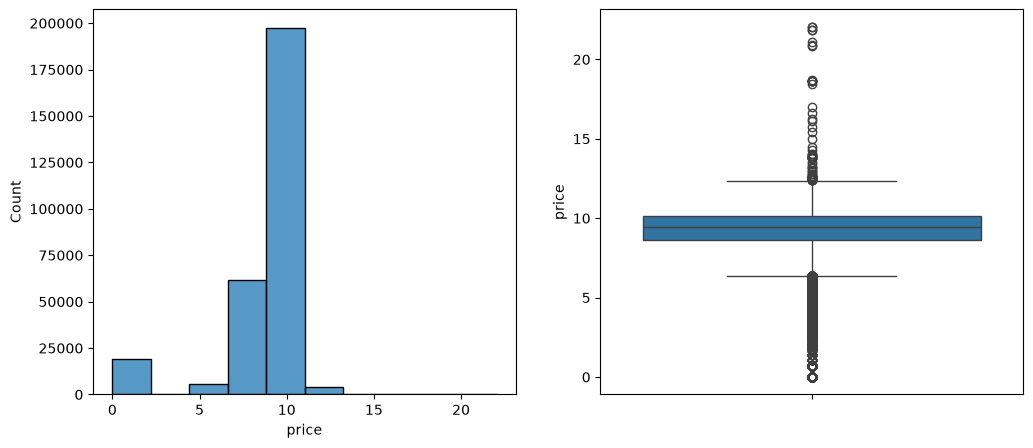

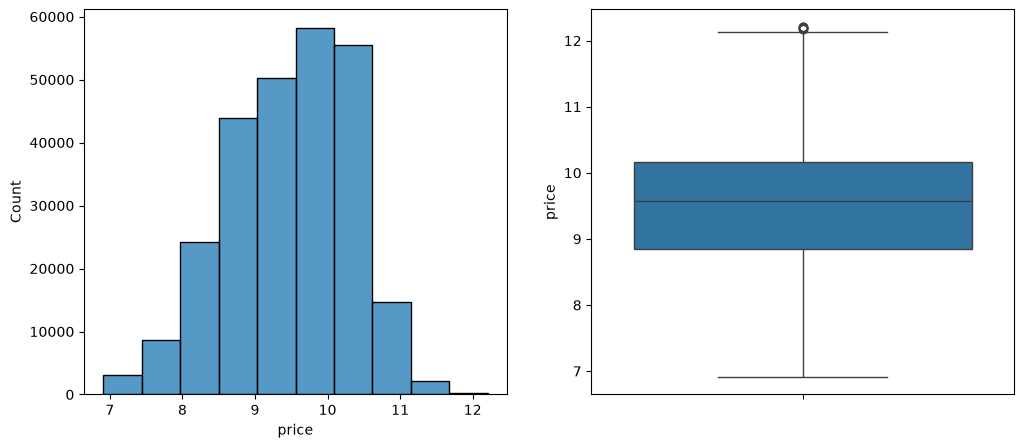

In [7]:

def price_visualizations(df):
    price=df['price']

    #Price audit
    min_price = price.min()
    max_price = price.max()
    print(f'Minimum price value is: {min_price}, and maximum price is {max_price}')

    #Detetmine inter quantile range(IQR)
    q1 = price.quantile(q=0.25)
    q3 = price.quantile(q=0.75)
    iqr = q3 - q1
    upper = q3 + 1.5*iqr

    print(f"IQR: {iqr}, Upper range based on IQR is: {upper}")

    df_price_counts = price.value_counts().reset_index().sort_values(by='price')
    print('Value counts of the price')
    print(df_price_counts)

    price_summary = pd.DataFrame({
        "Price range": [
            "Exactly $0",
            "$1-$99",
            "$100-$499",
            "$500-$1000",
            "$100,000-$199,999",
            "$200,000-$999999",
            "Above $1,000,000",
        ],
        "Count": [
            int(price.eq(0).sum()),
            int(price.between(1, 99).sum()),
            int(price.between(100, 499).sum()),
            int(price.between(500, 999).sum()),
            int(price.between(100000, 199999).sum()),
            int(price.between(200000, 999999).sum()),
            int(price.gt(1000000).sum()),
        ],
    })

    print('Price ranges')
    print(price_summary)

    log_price = np.log1p(price)

    fig = plt.figure(figsize=(12, 5))
    ax1 = plt.subplot(1, 2, 1)
    ax1 = sns.histplot(x=log_price, bins=10)

    ax2 = plt.subplot(1,2,2)
    ax2 = sns.boxplot(y=log_price)

print('VISUALIZATION BEFORE PRICE FILTERING')
price_visualizations(df=df)

price_filtering = (df['price']>1000) & (df['price']<=200000)
df = df[price_filtering].copy()

print('VISUALIZATION AFTER PRICE FILTERING')
price_visualizations(df=df)



#### Conclusions
Based on the results and the plots above the following decisions are made:
- Entries with prices lower than $1000 will be discarded due to fake or placeholder ads
- Entries with prices higher than $200,000 will be discarded due to low representation and fake prices
- The next step is to remove fake prices like 111111 / 1234567 / 9876543

#### Fake prices handling using pattern rules

In [8]:
def is_repetitive_digit(x): return len(x)>=4 and len(set(x)) == 1 and "9" not in set(x)
def is_sequence(x): return len(x)>=4 and (x in '01234567890123456789'
                                          or x in '98765432109876543210')

df_fake_prices = df.copy()

u = pd.Series(df['price'].unique())
s = u.astype(int).astype(str)
fake_pattern = set(u[s.map(is_repetitive_digit) | s.map(is_sequence)])
df_fake_prices['price_pattern'] = df_fake_prices['price'].isin(fake_pattern)

df_test = df[df_fake_prices['price_pattern']]

print(df_fake_prices['price_pattern'].value_counts())
print(df_test['price'].head(10))

df = df[~df_fake_prices['price_pattern']]
len(df)

price_pattern
False    260502
True        264
Name: count, dtype: int64
343      8888
1828    12345
5119     1234
7065     1234
7937    11111
7946    12345
7950     5555
7952     8765
7989    12345
8051     8888
Name: price, dtype: int64


260502

#### Conclusions
- There are 280 entries that respect the patterns. These entries are eliminated

#### Check skewness of price numerically and visually

1.8573794560243055 -0.33028787548434063


((array([-4.55169203, -4.36150052, -4.25834252, ...,  4.25834252,
          4.36150052,  4.55169203], shape=(260502,)),
  array([ 6.90975328,  6.91075079,  6.9117473 , ..., 12.20606765,
         12.20607265, 12.20607265], shape=(260502,))),
 (np.float64(0.8478148069352286),
  np.float64(9.482564827051593),
  np.float64(0.9924975446833253)))

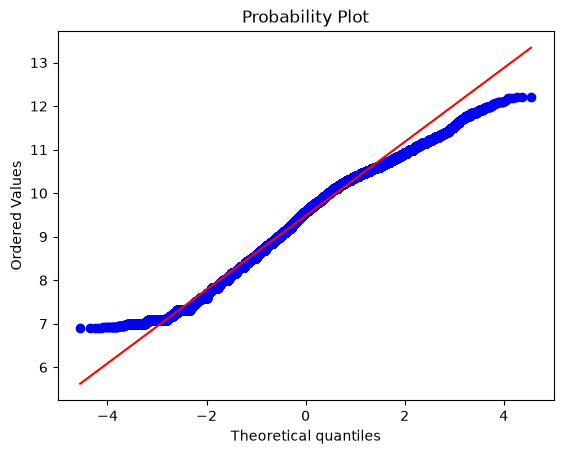

In [9]:
from scipy import stats

print(stats.skew(df['price']), stats.skew(np.log(df['price'])))
stats.probplot(np.log(df['price']), plot = plt)

#### Conclusions
- The shelf at the bottom is the price floor($1000) - many rows share the same value and the model won't predict below this level
- The fit through middle is very good
- The upper tail bends below the line because the expensive used cars are rarer than a normal distribution -> extreme high values won't dominate log-scale loss
- LOG TRANSFORMED PRICE WILL BE MAINTAINED FOR MODEL CREATION

### Step 3.2 Numeric Features
#### Step 3.2.1 Year

C:\Users\Rober\AppData\Local\Temp\ipykernel_17720\3865796008.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=90, ha="right",fontsize=5)
C:\Users\Rober\AppData\Local\Temp\ipykernel_17720\3865796008.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax2.set_xticklabels(ax.get_xticklabels(), rotation=90, ha="right",fontsize=5)


Total number of entries: 260502
Number of entries with age higher than 45 years: 5552
Share percentage of entries with age higher than 45 years: 2.131269625569099


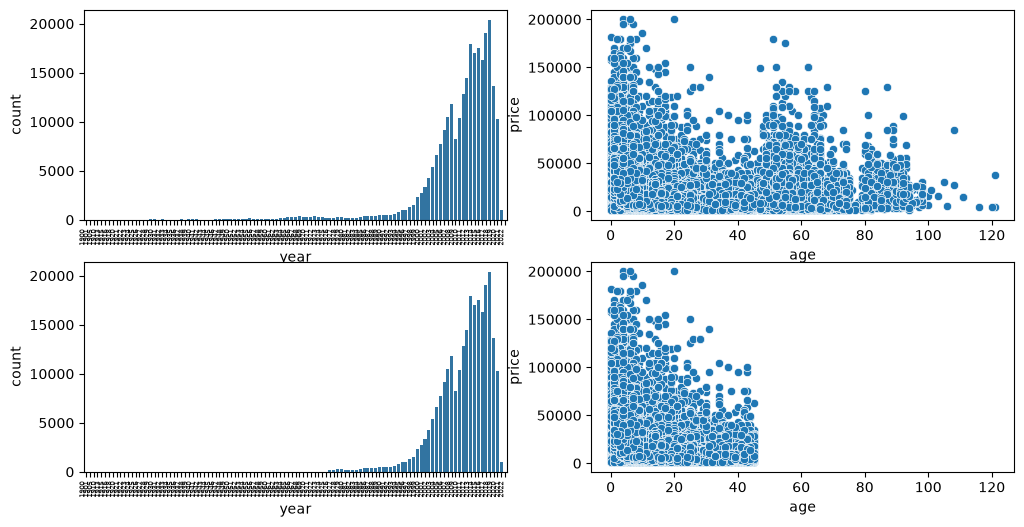

In [10]:
#List of years to maintain the same x axis for count vs year plot
years = sorted(df["year"].dropna().unique())


fig = plt.figure(figsize=(12, 6))
ax = plt.subplot(2, 2, 1)
ax = sns.countplot(data=df, x='year', order=years)
ax.set_xticklabels(ax.get_xticklabels(), rotation=90, ha="right",fontsize=5)

#Creation of age feature to compare fairly the age of the car at the moment of the listing
df['age'] = (df['posting_date'].dt.year - df['year']).clip(lower=0) # limit new cars to 0 year age

ax1 = plt.subplot(2, 2, 2)
ax1 = sns.scatterplot(data=df, x='age', y='price')

#Creation of regular cars(newer than 45 years) at the moment of the listing
regular_cars = df[df['age']<=45]

ax2 = plt.subplot(2, 2, 3)
ax2 = sns.countplot(data=regular_cars, x='year', order=years)
ax2.set_xticklabels(ax.get_xticklabels(), rotation=90, ha="right",fontsize=5)

ax3 = plt.subplot(2, 2, 4, sharex=ax1)
ax3 = sns.scatterplot(data=regular_cars, x='age', y='price')

print(f"Total number of entries: {len(df)}")
print(f"Number of entries with age higher than 45 years: {len(df) - len(regular_cars)}")
print(f"Share percentage of entries with age higher than 45 years: {(1 - len(regular_cars) / len(df)) *100}")

#Removal of classic cars over 45 years
df = df[df['age'] <= 45]


#### Conclusions

- Classic cars(over 45 years of age at the moment of the listing) represent a bit over 2% of the market share
- Price distribution as a function of age does not respect the trend and behave differently
- Classic cars were dropped from the analysis

#### Step 3.2.2 Odometer

count      254950.0
mean       102477.0
std        155695.0
min             0.0
0.1%            0.0
1%            102.0
5%           8794.0
25%         43000.0
50%         94000.0
75%        141500.0
95%        212038.0
99%        288000.0
99.9%     1000000.0
max      10000000.0
Name: odometer, dtype: float64


,rows,% of rows
0,474,0.186
1-99,1989,0.780
100-999,1848,0.725
300k-500k,1395,0.547
500k-1M,519,0.204
1M-10M,272,0.107


Rows with a pattern-like odometer: 305


,rows
odometer,
123456.0,73
1234.0,40
111111.0,34
12345.0,18
1111111.0,15
7777777.0,13
1234567.0,10
222222.0,8
98765.0,7


<Figure size 600x600 with 0 Axes>

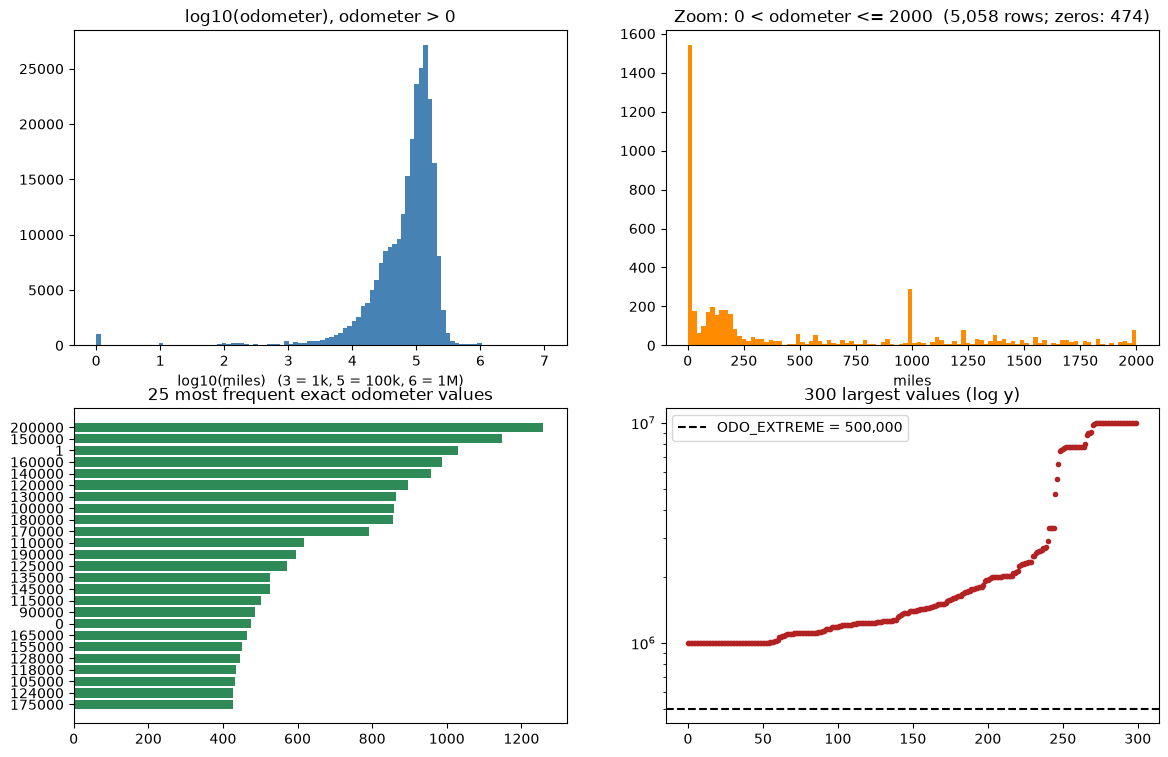

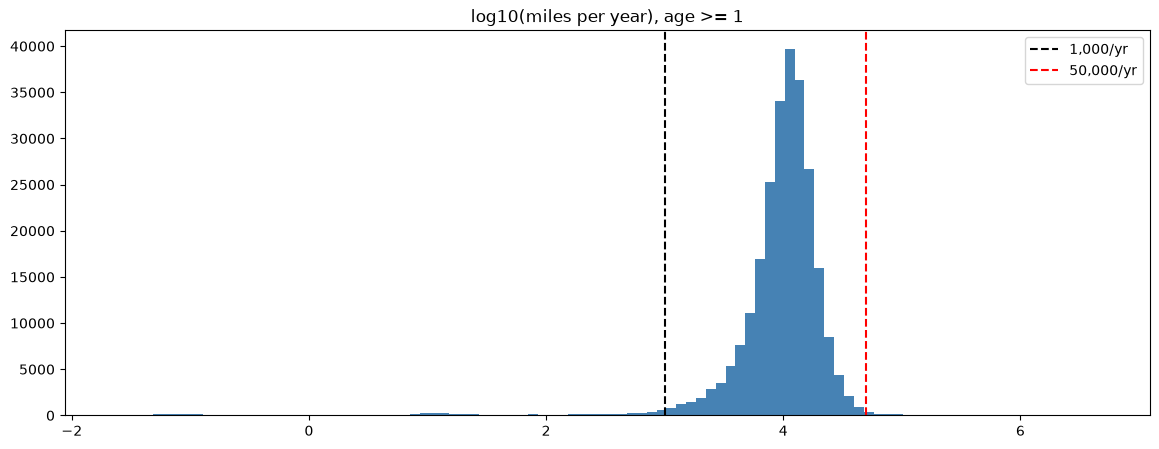

In [11]:
mpy_low = 1000 #low threshold of suspicious mileage
mpy_high = 50000 # high threshold of suspicious mileage
odo_max = 500000 # Maximum value for odometers


fig = plt.figure(figsize=(6,6))

df_odo = df.copy()

df_odo['log_price'] = np.log(df['price'])
df_odo['usable_age'] = df['age'].clip(lower=1) #Create this to be able to divide by age in miles per year calcualtion(MPY)
df_odo['mpy'] = df_odo['odometer']/df_odo['usable_age']
odo = df_odo['odometer']

#Create a numeric summary and count

print(odo.describe(percentiles=[0.001, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999]).round(0))

counts = {
    "0": (odo == 0).sum(),
    "1-99": odo.between(1, 99).sum(),
    "100-999": odo.between(100, 999).sum(),
    "300k-500k": odo.between(300_000, 500_000).sum(),
    "500k-1M": odo.between(500_000, 1_000_000).sum(),
    "1M-10M": odo.between(1_000_000, 10_000_000).sum()
}
summary = pd.Series(counts).to_frame("rows")
summary["% of rows"] = (summary["rows"] / len(df_odo) * 100).round(3)
display(summary)


#Distribution plots (outliers deliberately visible)
fig, ax = plt.subplots(2, 2, figsize=(14, 9))

# (a) whole range on a log axis
pos = odo[odo > 0]
ax[0, 0].hist(np.log10(pos), bins=100, color="steelblue")
ax[0, 0].set_title("log10(odometer), odometer > 0")
ax[0, 0].set_xlabel("log10(miles)   (3 = 1k, 5 = 100k, 6 = 1M)")
 
# (b) zoom on the low end
low = odo[(odo > 0) & (odo <= 2000)]
ax[0, 1].hist(low, bins=100, color="darkorange")
ax[0, 1].set_title(f"Zoom: 0 < odometer <= 2000  ({len(low):,} rows; zeros: {(odo == 0).sum():,})")
ax[0, 1].set_xlabel("miles")
 
# (c) most frequent exact values -> reveals placeholders (0, 123456, 999999...)
top_vals = odo.value_counts().head(25).sort_values()
ax[1, 0].barh(top_vals.index.astype(int).astype(str), top_vals.values, color="seagreen")
ax[1, 0].set_title("25 most frequent exact odometer values")
 
# (d) the 300 largest values
largest = np.sort(odo.dropna().values)[-300:]
ax[1, 1].semilogy(largest, ".", color="firebrick")
ax[1, 1].axhline(odo_max, color="k", ls="--", label=f"ODO_EXTREME = {odo_max:,}")
ax[1, 1].set_title("300 largest values (log y)")
ax[1, 1].legend()

#Placeholder-like patterns (flag only, do not drop on this alone)

def is_repetitive_digit(x): return len(x)>=4 and len(set(x)) == 1 and "9" not in set(x)
def is_sequence(x): return len(x)>=4 and (x in '01234567890123456789'
                                          or x in '98765432109876543210')

uniq = pd.Series(odo.unique())
fake_vals = uniq.astype(int).astype(str)
fake_pattern = set(uniq[fake_vals.map(is_repetitive_digit) | fake_vals.map(is_sequence)])
df_odo['odo_pattern'] = df_odo['odometer'].isin(fake_pattern)
 
print(f"Rows with a pattern-like odometer: {df_odo['odo_pattern'].sum():,}")
display(df_odo.loc[df_odo["odo_pattern"], "odometer"].value_counts().head(20).to_frame("rows"))


# %% 6. Miles per year and odometer vs age
fig, ax = plt.subplots(1, 1, figsize=(14, 5))

ok_mpy = df_odo[(df_odo["odometer"] > 0) & (df_odo["age"] >= 1)]
ax.hist(np.log10(ok_mpy["mpy"]), bins=100, color="steelblue")
ax.axvline(np.log10(mpy_low), color="k", ls="--", label=f"{mpy_low:,}/yr")
ax.axvline(np.log10(mpy_high), color="r", ls="--", label=f"{mpy_high:,}/yr")
ax.set_title("log10(miles per year), age >= 1")
ax.legend()


keep = (
    (df_odo["odometer"].between(0, odo_max))
    & (df_odo["age"] >= 1)
    & df_odo["mpy"].between(mpy_low, mpy_high)
    & ~df_odo["odo_pattern"]
)

df = df_odo.loc[keep].copy()

#### Conclusions
 - To be completed
 

### Step 2.3 Categorical features
#### Step 2.3.1 Normalize features

In [12]:
print(df.info())
categorical_features = ['region', 'manufacturer', 'condition', 'cylinders', 'fuel', 'transmission', 'drive', 'type', 'paint_color', 'state']
df_categorical = df.copy()

#Normalize values in each categorical feature by using lowercase and replacing whitespace with -
for feature in categorical_features:
    df[feature] = (
        df[feature]
        .str.lower()
        .str.strip()
        .str.replace(r'[^\w-]|_', '-', regex=True)
        .str.replace(r'\s+', '-', regex=True)
        .str.replace(r'-+', '-', regex=True)
        .str.strip('-')
    )


def _suggest(df):
    n = df['count_uniq_vals']
    notes = []

    if n <= 2:
        notes.append('binary/one-hot')
    elif n <= 15:
        notes.append("one-hot (ordinal if the levels have a natural order)")
    elif n <= 100:
        notes.append('one-hot or native categorical; target encoding is an option')
    else:
        notes.append('high cardinality: group rare levels + cross-fitted target encoding')

    if df['share_missing'] > 20:
        notes.append('keep missing as its own level/indicator')

    return "; ".join(notes)

cardinality_kpi = ['count_uniq_vals', 'rows_covered_top10', 'rows_covered_top50', 'share_missing']
rare_threshold = 30 #This is the maximum number of rows to be considered rare feature
cardinality_df = pd.DataFrame(columns=categorical_features, index=cardinality_kpi)


summaries = {}

for feature in categorical_features:
    column = df[feature]
    counts = column.value_counts()  # Compute once; reuse for both top-10 and top-50
    total = len(column)

    summaries[feature] = {
        "count_uniq_vals": column.nunique(),
        "rows_covered_top10": counts.head(10).sum() / total * 100,
        "rows_covered_top50": counts.head(50).sum() / total * 100,
        "share_missing": column.isna().mean() * 100,
    }

cardinality_df = pd.DataFrame.from_dict(summaries, orient="index")
cardinality_df["suggested_encoding"] = cardinality_df.apply(_suggest, axis=1)

cardinality_df


<class 'pandas.DataFrame'>
Index: 246807 entries, 27 to 426879
Data columns (total 20 columns):
 #   Column        Non-Null Count   Dtype              
---  ------        --------------   -----              
 0   region        246807 non-null  str                
 1   price         246807 non-null  int64              
 2   year          246807 non-null  int64              
 3   manufacturer  238805 non-null  str                
 4   model         246807 non-null  str                
 5   condition     161720 non-null  str                
 6   cylinders     154512 non-null  str                
 7   fuel          246807 non-null  str                
 8   odometer      246807 non-null  float64            
 9   transmission  246807 non-null  str                
 10  drive         176999 non-null  str                
 11  type          193279 non-null  str                
 12  paint_color   181318 non-null  str                
 13  state         246807 non-null  str                
 14  pos

,count_uniq_vals,rows_covered_top10,rows_covered_top50,share_missing,suggested_encoding
region,404,9.439359,40.585559,0.000000,high cardinality: group rare levels + cross-fi...
manufacturer,41,65.721394,96.757791,3.242209,one-hot or native categorical; target encoding...
condition,6,65.524884,65.524884,34.475116,one-hot (ordinal if the levels have a natural ...
cylinders,8,62.604383,62.604383,37.395617,one-hot (ordinal if the levels have a natural ...
fuel,5,100.000000,100.000000,0.000000,one-hot (ordinal if the levels have a natural ...
transmission,3,100.000000,100.000000,0.000000,one-hot (ordinal if the levels have a natural ...
drive,3,71.715551,71.715551,28.284449,one-hot (ordinal if the levels have a natural ...
type,13,76.626271,78.311798,21.688202,one-hot (ordinal if the levels have a natural ...
paint_color,12,72.867058,73.465501,26.534499,one-hot (ordinal if the levels have a natural ...
state,51,46.565535,99.871154,0.000000,one-hot or native categorical; target encoding...


In [13]:
# Setting all cylinders of electric cars to other since they don't have any cylinder
df.loc[df['fuel'].eq('electric'), 'cylinders'] = 'other'

# Verifyng condition column

condition_df = df_categorical.groupby('condition')['odometer'].mean().reset_index()
condition_df

df.columns

Index(['region', 'price', 'year', 'manufacturer', 'model', 'condition',
       'cylinders', 'fuel', 'odometer', 'transmission', 'drive', 'type',
       'paint_color', 'state', 'posting_date', 'age', 'log_price',
       'usable_age', 'mpy', 'odo_pattern'],
      dtype='str')

TypeError: Axis.set_ticks() missing 1 required positional argument: 'ticks'

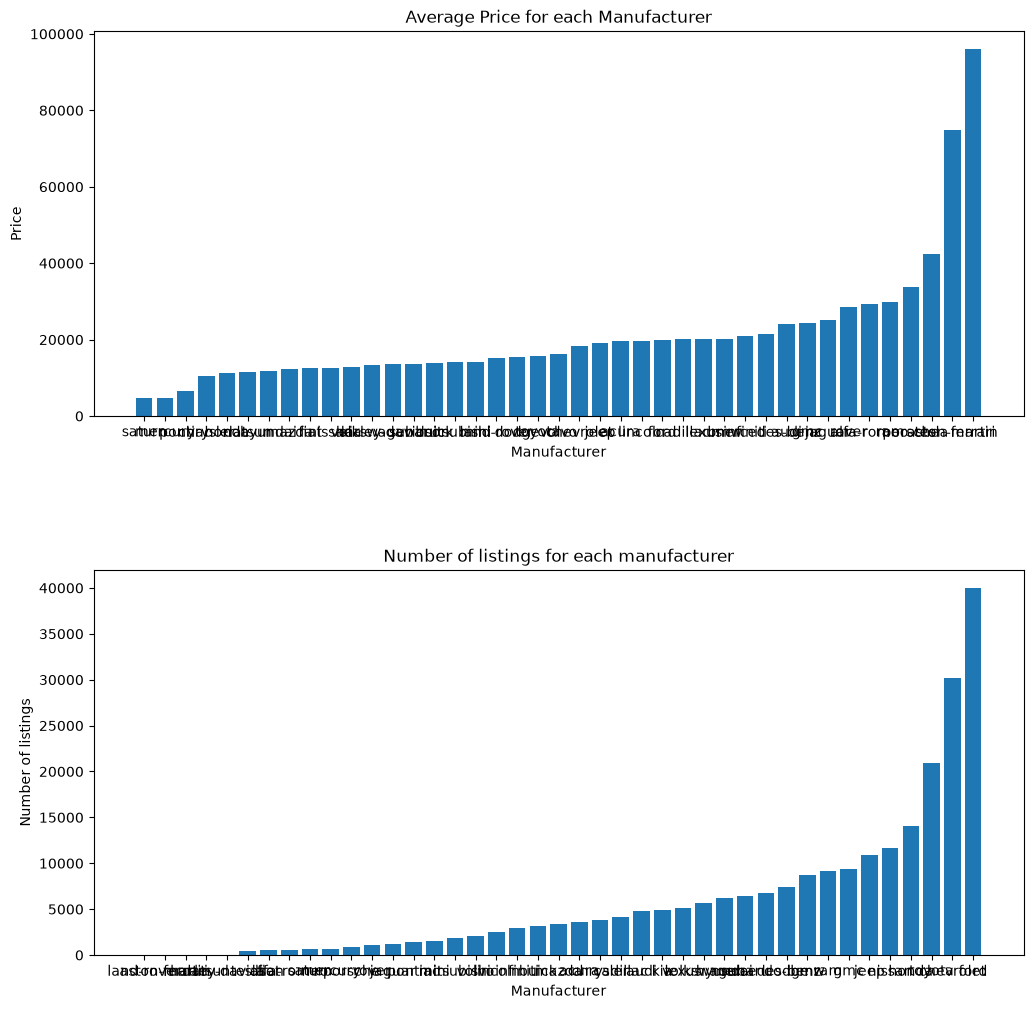

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12,12))
fig.subplots_adjust(hspace=0.4)

df_manuf_price = df.groupby('manufacturer')['price'].mean().reset_index().sort_values(by='price')

axes[0].bar(x=df_manuf_price['manufacturer'], height=df_manuf_price['price'])
axes[0].set_title('Average Price for each Manufacturer')
axes[0].set_xlabel('Manufacturer')
axes[0].set_ylabel('Price')
axes[0].set_xticks(ticksrotation=90)

df_manuf_listings = df.groupby('manufacturer')['posting_date'].count().reset_index().sort_values(by='posting_date')
axes[1].bar(x=df_manuf_listings['manufacturer'], height=df_manuf_listings['posting_date'])
axes[1].set_title('Number of listings for each manufacturer')
axes[1].set_xlabel('Manufacturer')
axes[1].set_ylabel('Number of listings')
axes[1].set_xticks(rotation=90)


In [23]:
df.columns

Index(['region', 'price', 'year', 'manufacturer', 'fuel', 'odometer',
       'transmission', 'state', 'posting_date', 'age', 'log_price',
       'usable_age', 'mpy', 'odo_pattern'],
      dtype='str')

### STEP idk

Dropping the columns with high number of missing values. Dropping the rows with nan manufacturer


In [33]:
from sklearn.preprocessing import OneHotEncoder

columns_to_drop = ['model', 'condition', 'cylinders', 'drive', 'type', 'paint_color']

enc = OneHotEncoder(sparse_output=False)

encoded_features = ['fuel', 'transmission']

enc_df = df.copy()

encoded_data = enc.fit_transform(df[encoded_features])

encoded_df = pd.DataFrame(
    encoded_data,
    columns = enc.get_feature_names_out(encoded_features),
    index=df.index
)



final_df = pd.concat(
    [df.drop(columns=encoded_features), encoded_df],
    axis = 1
)
final_df.head()

,region,price,year,manufacturer,odometer,state,posting_date,age,log_price,usable_age,mpy,odo_pattern,fuel_diesel,fuel_electric,fuel_gas,fuel_hybrid,fuel_other,transmission_automatic,transmission_manual,transmission_other
27,auburn,33590,2014,gmc,57923.0,al,2021-05-04 17:31:18+00:00,7,10.421984,7,8274.714286,False,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
28,auburn,22590,2010,chevrolet,71229.0,al,2021-05-04 17:31:08+00:00,11,10.025263,11,6475.363636,False,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
29,auburn,39590,2020,chevrolet,19160.0,al,2021-05-04 17:31:25+00:00,1,10.586332,1,19160.000000,False,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
30,auburn,30990,2017,toyota,41124.0,al,2021-05-04 15:41:31+00:00,4,10.341420,4,10281.000000,False,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
31,auburn,15000,2013,ford,128000.0,al,2021-05-03 19:02:03+00:00,8,9.615805,8,16000.000000,False,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0


## STEP X: Modeling

In [15]:
#Eliminate columns with high missing rates

df.isna().corr()

,region,price,year,manufacturer,model,condition,cylinders,fuel,odometer,transmission,drive,type,paint_color,state,posting_date,age,log_price,usable_age,mpy,odo_pattern
region,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
manufacturer,NaN,NaN,NaN,1.000000,NaN,-0.035747,0.000244,NaN,NaN,NaN,0.023856,0.044712,0.006928,NaN,NaN,NaN,NaN,NaN,NaN,NaN
model,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
condition,NaN,NaN,NaN,-0.035747,NaN,1.000000,0.339890,NaN,NaN,NaN,0.194062,0.261031,0.247058,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cylinders,NaN,NaN,NaN,0.000244,NaN,0.339890,1.000000,NaN,NaN,NaN,0.435246,0.300576,0.305923,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fuel,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
odometer,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transmission,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
